In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:
%matplotlib inline
sys.path.append("..")
import wavelet_transform.utils.training_data as train
import wavelet_transform.postprocess.plotting as plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Set pararmeters for bubble dynamics model

In [3]:
pac = -5E5                                  # the amplitude of the sine wave in Pa
frequency = 5E5                  # insonation frequency (Hz)
no_cycle = 20                               # no. of cycles of the sine wave
sampling_rate = 500E6      # sampling rate to generate the time vector
real_sampling_rate = 25E6
tstep = 1. / sampling_rate
tmax = no_cycle / frequency
time = np.arange(0., tmax, tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.01

wavelet = "db20"
levels = 4
mode = "symmetric"

fft_lim = 10 * frequency  # increase value to view more of the fft plots

### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.

In [4]:
i = 0
wpt_df = None
for frequency in [i * 1E5 for i in range(8, 10)]:
    for pac in [-i * 1E4 for i in range(1, 20)]:
        data = train.generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
        if max(data) > 70 or np.isnan(data).any():  # filter out failed dynamics model computations
            continue
        data = (data - np.mean(data))/np.std(data)
        # data += np.random.normal(0, std_noise, size=len(data))

        # data = np.random.normal(0, std_noise, size=len(data))

        i += 1
        # plt.plot(data)
        # plt.title(f"Frequency: {frequency}, pac: {pac}")
        # plt.show()
        step = int(sampling_rate/real_sampling_rate)
        training_data = train.generate_training_data(
            data[::step], levels, wavelet, mode, min_energy=0.01, add_noise=1
        )
        if wpt_df is None:
            wpt_df = training_data
        else:
            wpt_df = pd.concat([wpt_df, training_data], ignore_index=True)

print(i)  # print number of signals in training data

nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
38


### Training

Train fuzzy c-means on the generated data

In [55]:
from sklearn.preprocessing import StandardScaler
import skfuzzy as fuzz

# Get data
wpt_df
classifying_metrics = ["energy", "crest factor", "spectral entropy", "log energy"]
data_train = wpt_df[classifying_metrics]

# Standardise data
scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# Parameters for Fuzzy C-means
no_clusters = 10
m = 5
error = 1e-6

# Fuzzy C-Means clustering
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    data_train_normalised.T,
    c=no_clusters,
    m=m,
    error=error,
    maxiter=100,
)
print("number of iterations:", p)
# Cluster centres
centers = scaler.inverse_transform(cntr)
print("centers:", centers)
# Membership matrix
membership_matrix = u.T

# Hard cluster assignments
labels = np.argmax(membership_matrix, axis=1)
for i in range(no_clusters):
    print(f"label {i} count:", list(labels).count(i))

# membership_results = pd.DataFrame()
# for i, membership in enumerate(membership_matrix):
#     membership_results.loc[i, "hard assignment"] = labels[i]
#     for j in range(no_clusters):
#         membership_results.loc[i, f"membership {j}"] = membership[j]

# membership_results.head()

number of iterations: 99
centers: [[ 0.06697766  4.48274471  5.91635547 -2.85470212]
 [ 0.06332338  3.9193331   5.91655672 -2.88667528]
 [ 0.06702145  4.48183453  5.91631411 -2.85473116]
 [ 0.02447819  6.62175277  5.96242974 -2.02983148]
 [ 4.54206914  3.11748031  4.80185855  0.65331351]
 [ 0.02678807  3.4488183   5.9423363  -2.88192589]
 [ 0.04949803  3.72875561  5.9204323  -2.8771771 ]
 [ 0.06637786  4.1124912   5.90725525 -2.85809215]
 [ 7.4086594   1.95035211  3.99490021  0.86905879]
 [ 0.0521313   5.27321154  5.93454431 -2.69189434]]
label 0 count: 38
label 1 count: 46
label 2 count: 33
label 3 count: 62
label 4 count: 12
label 5 count: 108
label 6 count: 39
label 7 count: 43
label 8 count: 45
label 9 count: 54


Plotting clustering results

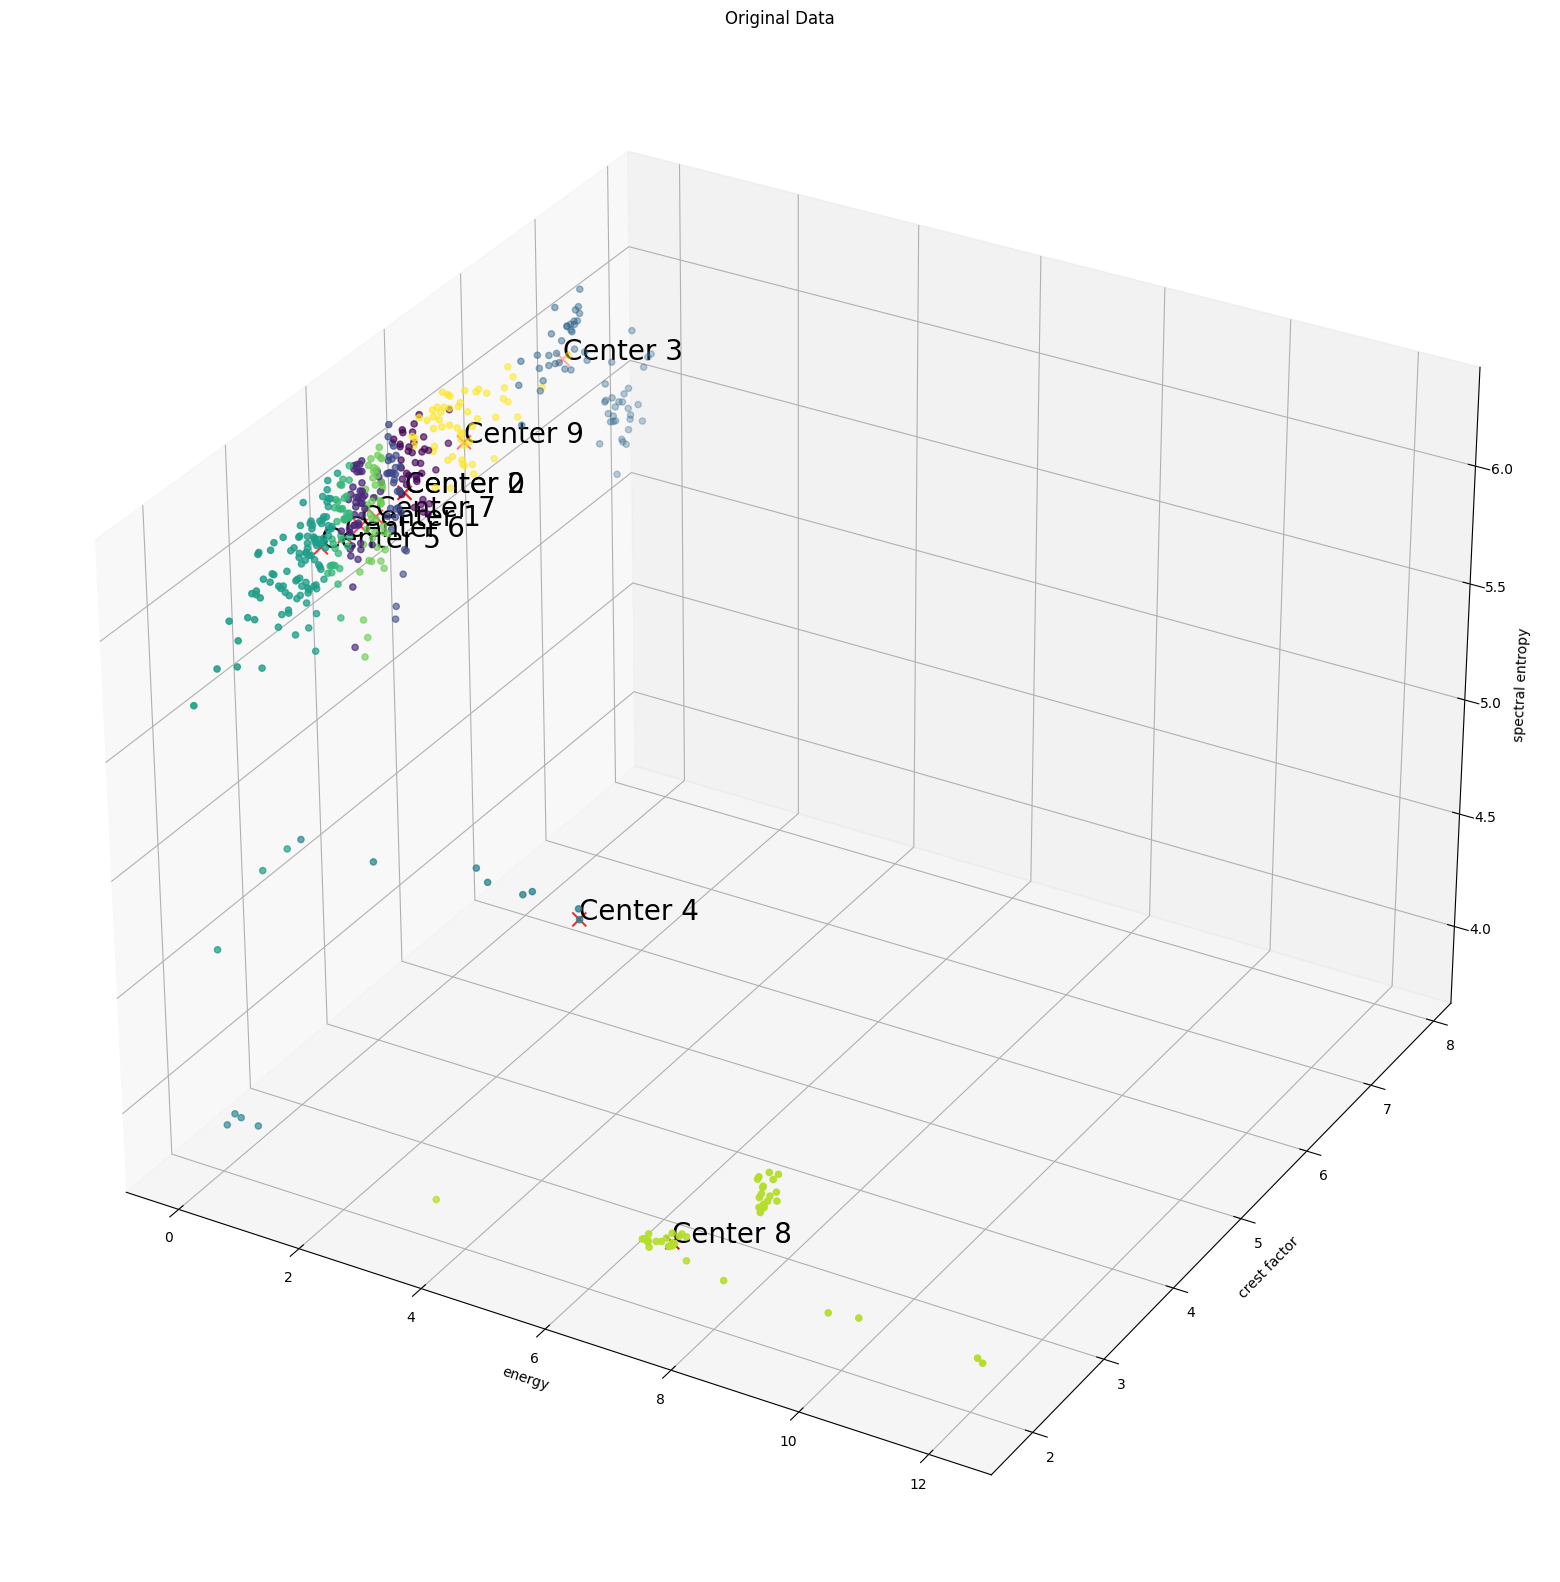

In [56]:
fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(111, projection="3d")

title = "Original Data"

data_scatter = data_train.values.tolist()
centers_scatter = centers
color_map_labels = labels

# Plot data points
data_plot = ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=color_map_labels
)

# Plot cluster centers after data points
center_plot = ax.scatter(
    centers_scatter[:, 0],
    centers_scatter[:, 1],
    centers_scatter[:, 2],
    c="red",
    marker="x",
    s=100,
)

# Annotate cluster centers with their positions
for i, center in enumerate(centers_scatter):
    ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

ax.set_xlabel(data_train.columns[0])
ax.set_ylabel(data_train.columns[1])
ax.set_zlabel(data_train.columns[2])
ax.set_title(title)

plt.show()

### Classifying new data points

dynamics is inconsistent
clustering works better with fewer levels
need better standardisation of data

nodes kept: 16/16


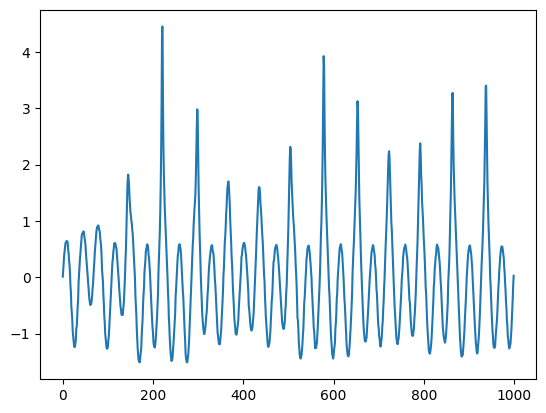

In [57]:
frequency = 7E5
pac = -2E5

min_energy = 0  # Only nodes with energy at least min_energy * total_energy will be considered

data = train.generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
data = (data - np.mean(data)) / np.std(data)
data += np.random.normal(0, std_noise, len(data))
data = data[::step]

new_wpt_df, new_tr_ob = train.generate_training_data(
    data, 
    levels,
    wavelet, 
    mode,
    min_energy=min_energy,
    include_tr_ob=True
)

new_wpt_df.head()

plt.plot(data)
plt.show()

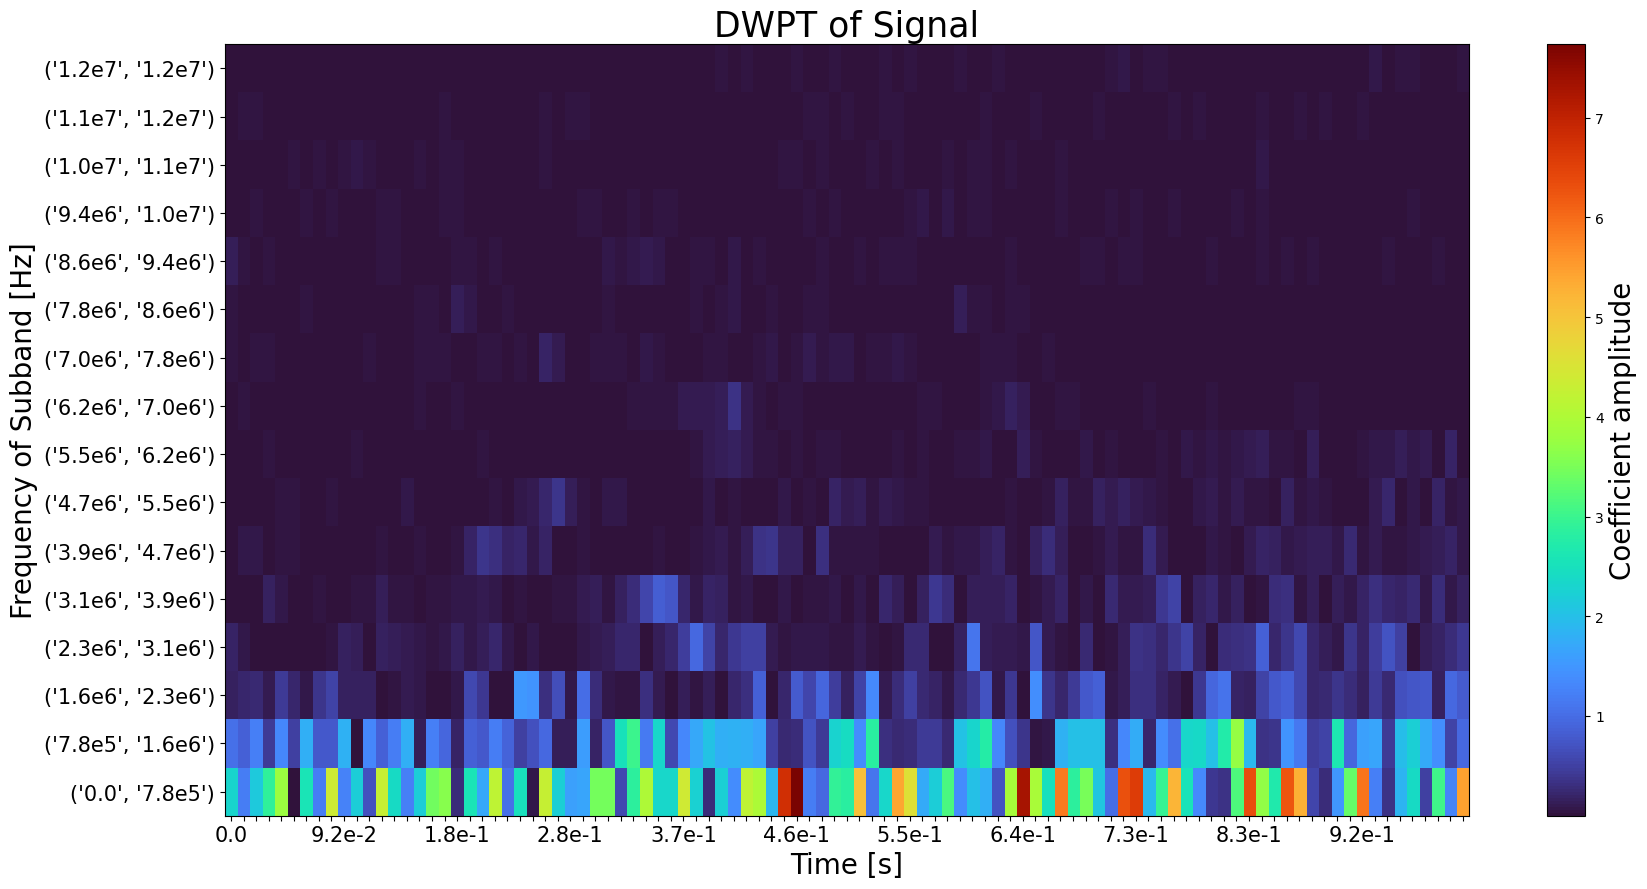

In [58]:
new_tr_ob.calc_frequencies(real_sampling_rate)
plot.heisenberg(new_tr_ob)

In [59]:
# New testing data from signal
new_entry = new_wpt_df[classifying_metrics]

# Standardize the new entry using the same scaler
new_entry_normalized = scaler.transform(new_entry)

# Predict membership using the cluster centers and membership matrix
new_u, *_ = fuzz.cluster.cmeans_predict(
    new_entry_normalized.T,
    cntr,
    m=m,
    error=error,
    maxiter=100,
)

new_membership_matrix = new_u.T
# Convert membership to hard cluster assignment
new_labels = np.argmax(new_u, axis=0)

# Display the predicted results
print("Predicted hard cluster assignment:", new_labels)

membership_results = pd.DataFrame()
for i, membership in enumerate(new_membership_matrix):
    membership_results.loc[i, "hard assignment"] = new_labels[i]
    for j in range(no_clusters):
        membership_results.loc[i, f"membership {j}"] = membership[j]

membership_results

Predicted hard cluster assignment: [8 4 9 9 9 6 3 9 3 3 5 6 6 0 5 2]


,hard assignment,membership 0,membership 1,membership 2,membership 3,membership 4,membership 5,membership 6,membership 7,membership 8,membership 9
0,8.0,0.089013,0.089095,0.089014,0.088001,0.130252,0.088857,0.089076,0.089193,0.158812,0.088686
1,4.0,0.093436,0.094763,0.093440,0.086741,0.159120,0.095096,0.095135,0.094675,0.096515,0.091078
2,9.0,0.109138,0.105595,0.109135,0.106858,0.081119,0.101713,0.104303,0.107463,0.062919,0.111757
3,9.0,0.111913,0.104668,0.111903,0.114120,0.071745,0.098553,0.102348,0.107694,0.056947,0.120107
4,9.0,0.116415,0.109604,0.116408,0.099196,0.065267,0.102650,0.107041,0.112827,0.052301,0.118290
5,6.0,0.113378,0.122321,0.113397,0.076886,0.060359,0.122722,0.123891,0.120758,0.048713,0.097575
6,3.0,0.097557,0.087838,0.097538,0.228731,0.060083,0.081737,0.085215,0.090864,0.050376,0.120061
7,9.0,0.120730,0.093681,0.120668,0.087925,0.046562,0.081078,0.087969,0.101041,0.038472,0.221874
8,3.0,0.103953,0.097116,0.103941,0.152152,0.074640,0.092429,0.095118,0.099278,0.064572,0.116800
9,3.0,0.104369,0.093904,0.104349,0.176458,0.063868,0.087251,0.091027,0.097114,0.054293,0.127367


### Reconstructing by cluster

Reconstructed nodes by group:


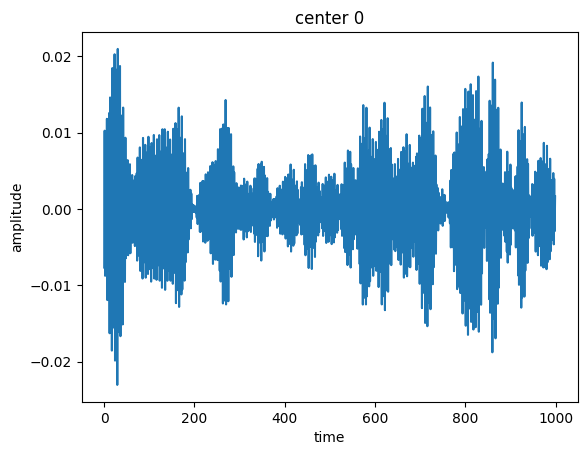

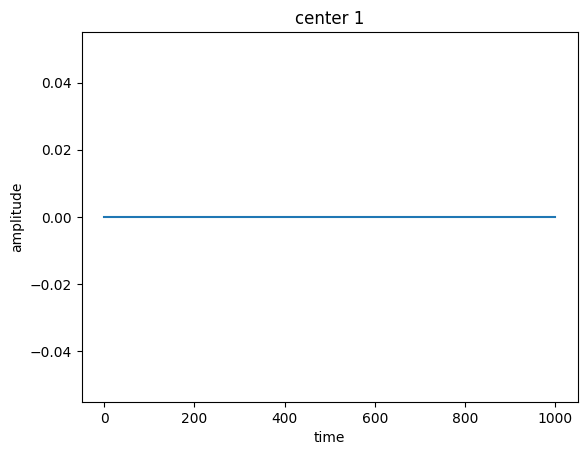

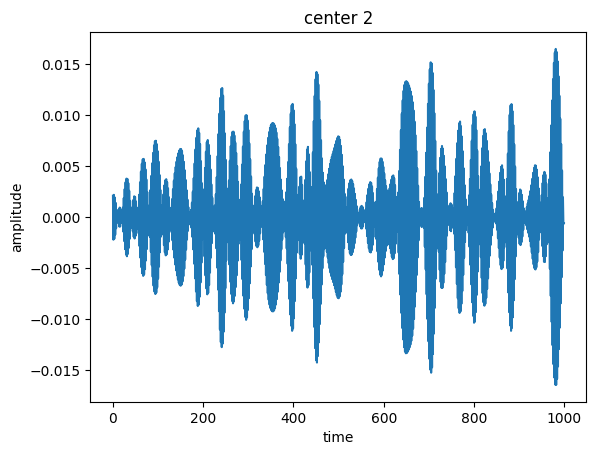

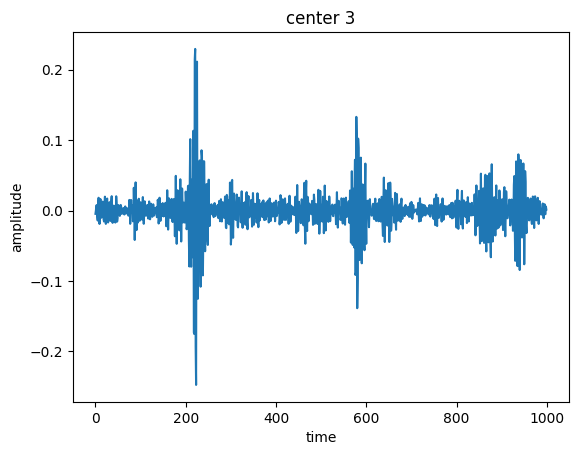

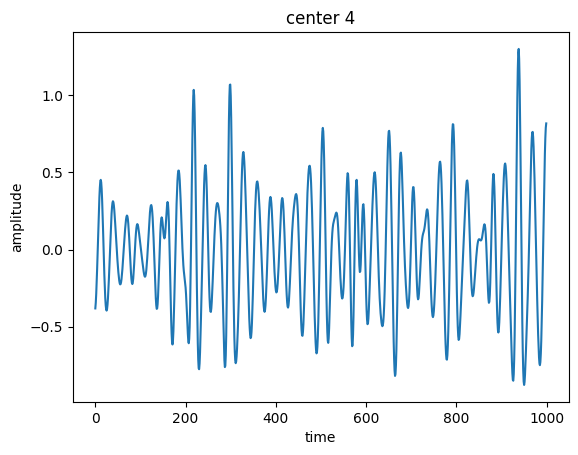

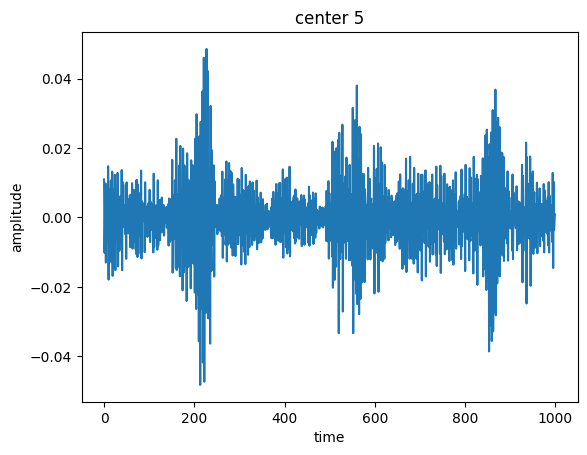

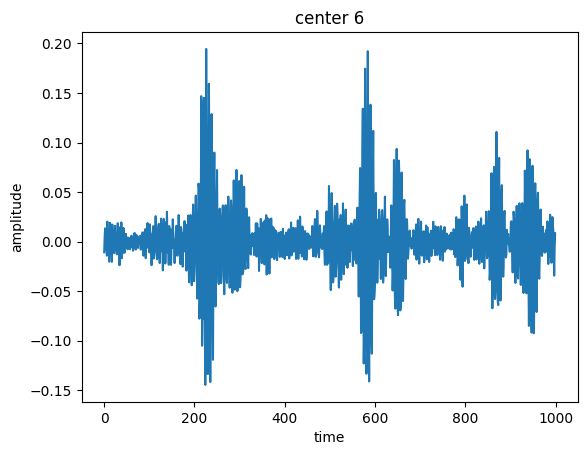

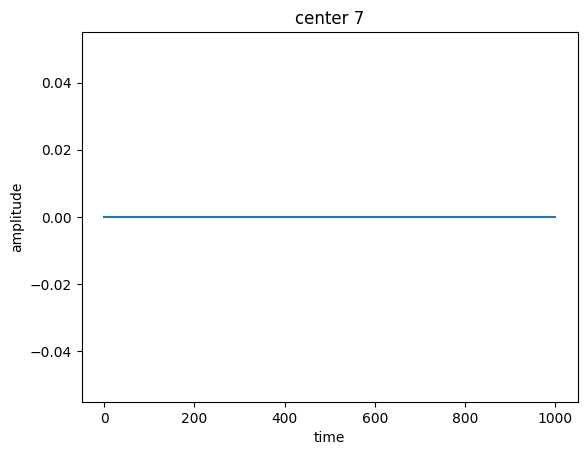

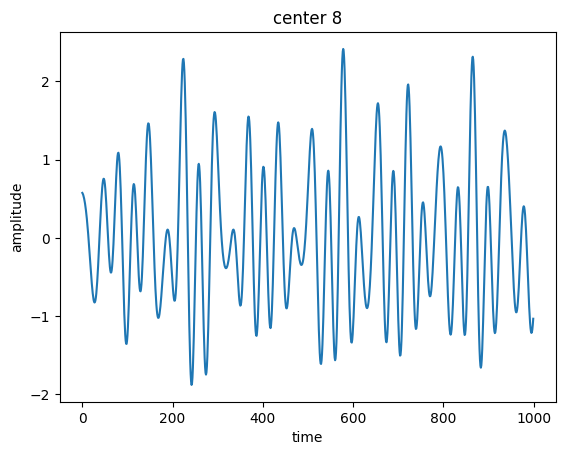

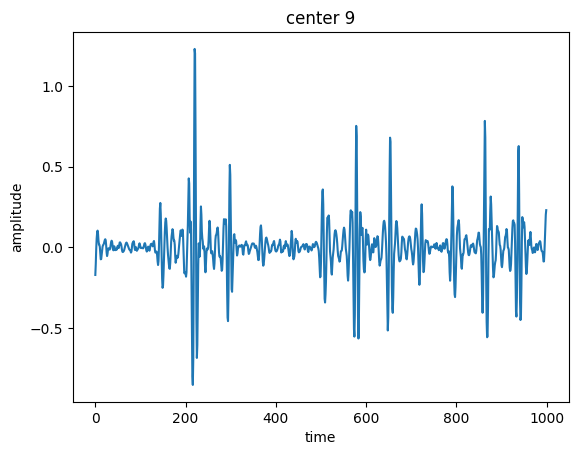

In [60]:
# Sum all reconstructions belonging to the same group
plot.plot_reconstructions_by_group(new_tr_ob, new_labels, no_clusters, order="freq")

### Plot nodes

Plot each node in the test data set alongside its membership values. Filter by the centre the node is assigned to.

0.037557693603113375


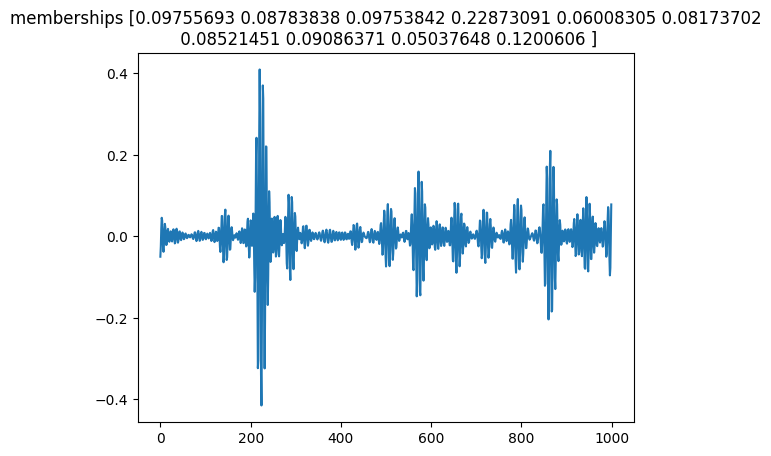

0.0004685050875766333


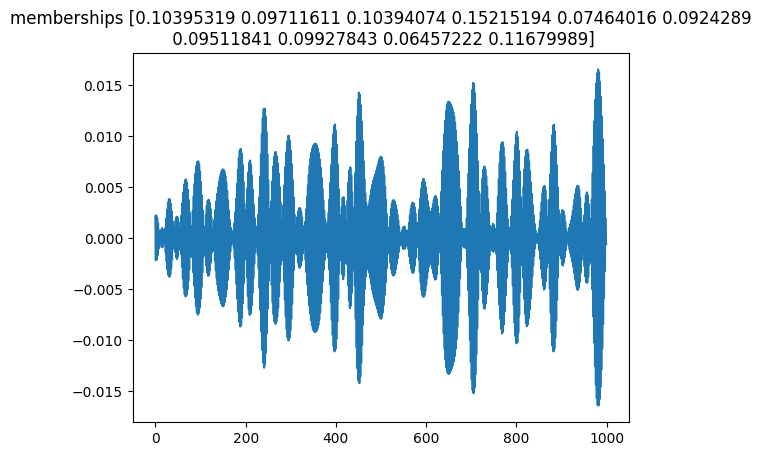

0.0005167381913870251


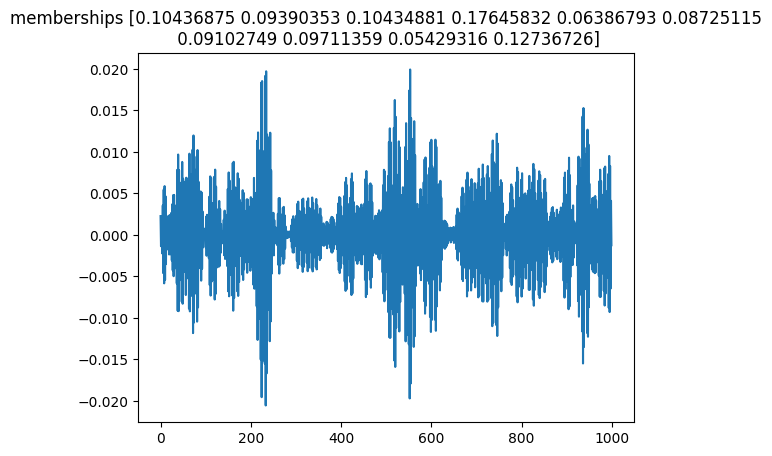

In [61]:
import wavelet_transform.wpt.inverse_transform as inv
run = True
if run is True:
    plot_centres = [3]
    for i, (node, assignment) in enumerate(zip(new_tr_ob.get_level(), new_labels)): 
        if assignment in plot_centres:
            print(node.energy)
            rec = inv.inv_dwpt(new_tr_ob, levels, nodes=node)
            plt.plot(rec)
            plt.title(f"memberships {new_membership_matrix[i]}")
            plt.show()